# Chapitre 11 - Lab : un journal partitionné réel avec Kafka

Le cours 2 a construit un journal partitionné jouet (`st.PartitionedLog`). Ce lab refait
les mêmes expériences sur un vrai courtier, Apache Kafka 3.7 (mode KRaft, un seul nœud) :
partitions et clés, groupes de consommateurs et rééquilibrage, offsets validés et
doublons après une panne, rejeu, rétention et compaction. Le client Python est
`kafka-python-ng`.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/streams/compose.yml -p ddia_streams up -d --wait
# ... exécuter le notebook ...
docker compose -f docker/streams/compose.yml -p ddia_streams down -v
```

Kafka écoute sur le port **11292** de l'hôte. (Le même fichier démarre aussi le
PostgreSQL du lab de capture des changements.)

**Plan.**

1. Un sujet, ses partitions et le partitionneur des clés.
2. Groupes de consommateurs et rééquilibrage.
3. Offsets validés, retard et doublons après une panne.
4. Rejouer : nouveau groupe, retour à un offset, retour à un instant.
5. Rétention : le début du journal avance.
6. Compaction : la dernière valeur de chaque clé.

In [1]:
import json
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from kafka import KafkaAdminClient, KafkaConsumer, KafkaProducer, TopicPartition
from kafka.admin import NewTopic
from kafka.errors import UnknownTopicOrPartitionError
from kafka.structs import OffsetAndMetadata

from ddia import streams as st
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
B = "localhost:11292"
admin = KafkaAdminClient(bootstrap_servers=B, client_id="lab")
print("courtier joignable ; sujets existants :", sorted(t for t in admin.list_topics() if not t.startswith("__")))


def nouveau_sujet(nom, partitions=1, **config):
    """(Re)crée un sujet vide, pour que le notebook puisse être relancé."""
    try:
        admin.delete_topics([nom])
        while nom in admin.list_topics():
            time.sleep(0.2)
        time.sleep(1.0)
    except UnknownTopicOrPartitionError:
        pass
    admin.create_topics([NewTopic(nom, partitions, 1, topic_configs={k.replace("_", "."): str(v) for k, v in config.items()})])
    time.sleep(0.5)


def producteur():
    return KafkaProducer(bootstrap_servers=B, key_serializer=lambda k: None if k is None else k.encode(),
                         value_serializer=lambda v: None if v is None else json.dumps(v).encode(), linger_ms=5)


def lire_tout(sujet, groupe=None, timeout=4.0):
    """Lit un sujet depuis le début (sans groupe : aucune trace côté courtier)."""
    c = KafkaConsumer(bootstrap_servers=B, group_id=groupe, auto_offset_reset="earliest", enable_auto_commit=False,
                      key_deserializer=lambda k: k and k.decode(), value_deserializer=lambda v: v and json.loads(v))
    parts = [TopicPartition(sujet, p) for p in c.partitions_for_topic(sujet)]
    c.assign(parts)
    c.seek_to_beginning(*parts)
    fin = c.end_offsets(parts)
    out, t0 = [], time.time()
    while time.time() - t0 < timeout and any(c.position(tp) < fin[tp] for tp in parts):
        for tp, recs in c.poll(300).items():
            out += recs
    c.close()
    return out

courtier joignable ; sujets existants : []


## 1. Un sujet, ses partitions et le partitionneur (section *Using logs for message storage*)

On crée un sujet `clics` de 6 partitions, puis on produit 6 000 messages dont la clé est
l'identifiant d'un utilisateur parmi 200. Pour chaque message, le courtier renvoie la
partition et l'offset attribués. On vérifie que la partition est exactement celle que
calcule notre implémentation du partitionneur de Kafka (`st.kafka_partition`, murmur2), que
les offsets sont contigus dans chaque partition et que l'ordre par clé est préservé.

partitions identiques à st.kafka_partition : True ; offsets contigus : True ; ordre par clé préservé à la lecture : True


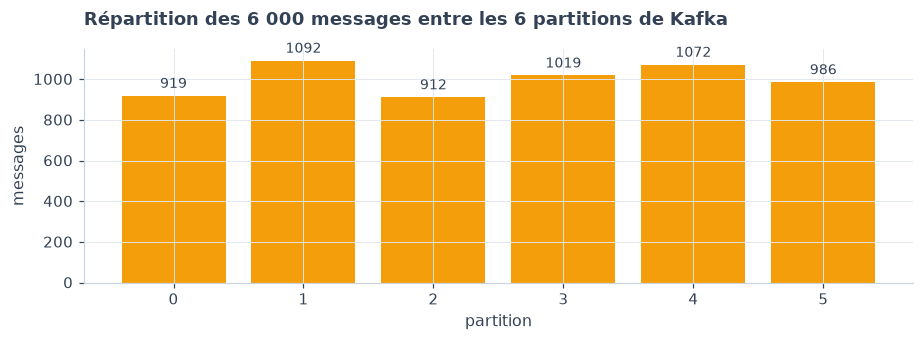

In [2]:
nouveau_sujet("clics", 6)
prod = producteur()
rng = np.random.default_rng(0)
envois = []
for i in range(6000):
    u = f"user-{int(rng.integers(0, 200))}"
    envois.append((u, i, prod.send("clics", key=u, value={"user": u, "seq": i})))
prod.flush()
meta = [(u, i, f.get().partition, f.get().offset) for u, i, f in envois]
M = pd.DataFrame(meta, columns=["clé", "seq", "partition", "offset"])
ok_part = all(p == st.kafka_partition(u, 6) for u, _, p, _ in meta)
ok_off = all(sorted(g.offset) == list(range(len(g))) for _, g in M.groupby("partition"))
recs = lire_tout("clics")
par_cle = {}
for r in recs:
    par_cle.setdefault(r.key, []).append(r.value["seq"])
ok_ordre = all(v == sorted(v) for v in par_cle.values())
print(f"partitions identiques à st.kafka_partition : {ok_part} ; offsets contigus : {ok_off} ; "
      f"ordre par clé préservé à la lecture : {ok_ordre}")
fig, ax = plt.subplots(figsize=(8.5, 3.2))
cnt = M.groupby("partition").size()
ax.bar(cnt.index, cnt.values, color=AMBER)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("partition"); ax.set_ylabel("messages")
ax.set_title("Répartition des 6 000 messages entre les 6 partitions de Kafka")
plt.tight_layout(); plt.show()

Notre fonction de 20 lignes reproduit exactement le choix du client Java de Kafka : un
producteur dans n'importe quel langage qui hache la clé de la même façon envoie la même
clé dans la même partition, ce qui permet de garantir l'ordre par clé. La lecture à
travers les 6 partitions entrelace les clés, mais respecte l'ordre de chacune.

> **À retenir.** Kafka attribue la partition par murmur2(clé) modulo le nombre de
> partitions, et des offsets contigus dans chaque partition ; l'ordre n'est garanti qu'au
> sein d'une partition.

## 2. Groupes de consommateurs et rééquilibrage (section *Logs compared to traditional messaging*)

Trois consommateurs d'un même groupe se succèdent : C1 démarre seul, C2 le rejoint au
bout de 4 s, C3 au bout de 8 s, puis C3 s'arrête proprement à 14 s. À chaque arrivée ou
départ, le coordinateur du groupe **rééquilibre** l'affectation des partitions (stratégie
« range » par défaut). Chaque consommateur tourne dans un fil et note son affectation à
chaque appel de `poll`.

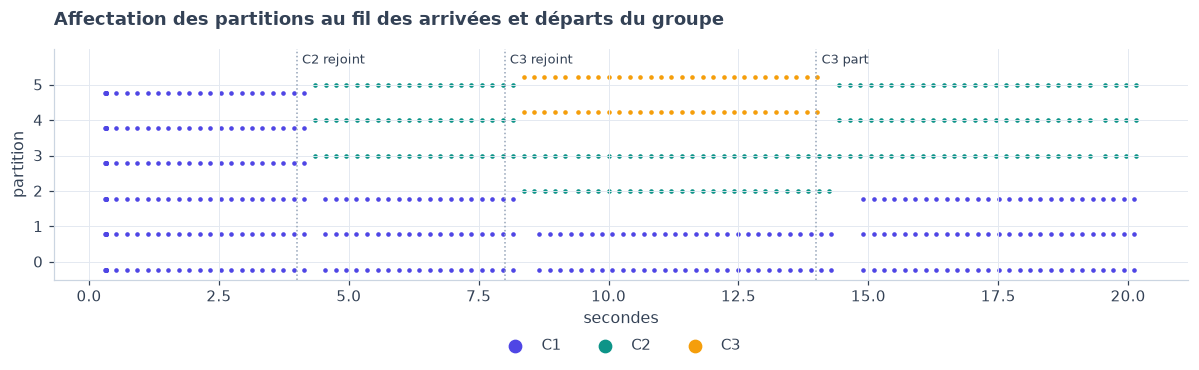

,vers t = 7 s,vers t = 13 s,vers t = 19 s
membre,,,
C1,"[0, 1, 2]","[0, 1]","[0, 1, 2]"
C2,"[3, 4, 5]","[2, 3]","[3, 4, 5]"
C3,None,"[4, 5]",None


In [3]:
journal_aff, verrou = [], threading.Lock()
t_ref = time.time()

def membre(nom, groupe, debut, fin, sujet="clics"):
    time.sleep(debut)
    c = KafkaConsumer(sujet, bootstrap_servers=B, group_id=groupe, client_id=nom, auto_offset_reset="earliest",
                      enable_auto_commit=True, session_timeout_ms=6000, heartbeat_interval_ms=1000)
    while time.time() - t_ref < fin:
        c.poll(200)
        with verrou:
            journal_aff.append((time.time() - t_ref, nom, sorted(tp.partition for tp in c.assignment())))
    c.close()

fils = [threading.Thread(target=membre, args=(n, "groupe-demo", d, f)) for n, d, f in
        [("C1", 0, 20), ("C2", 4, 20), ("C3", 8, 14)]]
for f in fils:
    f.start()
for f in fils:
    f.join()
A = pd.DataFrame(journal_aff, columns=["t", "membre", "partitions"])
fig, ax = plt.subplots(figsize=(11, 3.6))
for k, (nom, c) in enumerate([("C1", INDIGO), ("C2", TEAL), ("C3", AMBER)]):
    sub = A[A.membre == nom]
    for p in range(6):
        possede = sub.partitions.apply(lambda ps: p in ps).values
        ts = sub.t.values
        ax.scatter(ts[possede], np.full(possede.sum(), p + (k - 1) * 0.22), s=4, color=c, label=nom if p == 0 else None)
for t, lab in [(4, "C2 rejoint"), (8, "C3 rejoint"), (14, "C3 part")]:
    ax.axvline(t, color=GRAY, ls=":", lw=1)
    ax.text(t + 0.1, 5.6, lab, fontsize=8.5, color=SLATE)
ax.set_yticks(range(6)); ax.set_ylabel("partition"); ax.set_xlabel("secondes")
ax.set_ylim(-0.5, 6.0)
ax.set_title("Affectation des partitions au fil des arrivées et départs du groupe")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), markerscale=4, ncol=3)
plt.tight_layout(); plt.show()
derniers = A.groupby("membre").apply(lambda g: [g[g.t < 7.5].partitions.iloc[-1] if (g.t < 7.5).any() else None,
                                                g[(g.t > 10) & (g.t < 13.5)].partitions.iloc[-1] if ((g.t > 10) & (g.t < 13.5)).any() else None,
                                                g[g.t > 17].partitions.iloc[-1] if (g.t > 17).any() else None])
pd.DataFrame(derniers.tolist(), index=derniers.index, columns=["vers t = 7 s", "vers t = 13 s", "vers t = 19 s"])

Chaque partition a toujours **un seul** propriétaire dans le groupe : C1 a d'abord les 6,
puis les partage avec C2 (3 + 3), puis chacun en a 2 ; au départ de C3, ses partitions
sont redistribuées. Pendant un rééquilibrage, la consommation s'interrompt brièvement
(les trous dans les points). Que se passe-t-il avec plus de membres que de partitions ?

In [4]:
journal_aff.clear()
t_ref = time.time()
fils = [threading.Thread(target=membre, args=(f"M{i}", "groupe-trop-grand", 0, 12)) for i in range(1, 9)]
for f in fils:
    f.start()
time.sleep(9)                                           # le groupe est stable : on interroge le coordinateur
g = admin.describe_consumer_groups(["groupe-trop-grand"])[0]
aff = {m.client_id: [p for _, ps in m.member_assignment.assignment for p in ps] for m in g.members}
for f in fils:
    f.join()
print("état du groupe :", g.state)
print({m: aff[m] for m in sorted(aff)})
print("membres inactifs :", sorted(m for m, p in aff.items() if not p))

état du groupe : Stable
{'M1': [0], 'M2': [1], 'M3': [2], 'M4': [3], 'M5': [4], 'M6': [5], 'M7': [], 'M8': []}
membres inactifs : ['M7', 'M8']


Avec 8 membres pour 6 partitions, deux membres n'ont rien à lire : le parallélisme d'un
groupe est plafonné par le nombre de partitions, comme annoncé au cours 2.

> **À retenir.** Le coordinateur affecte les partitions entières aux membres du groupe et
> rééquilibre à chaque arrivée ou départ ; au-delà du nombre de partitions, les membres
> supplémentaires sont inactifs.

## 3. Offsets validés, retard et doublons (section *Consumer offsets*)

Un consommateur du groupe `facturation` traite les messages de la partition 0, valide son
offset tous les 100 messages, et « tombe en panne » (on ferme le client sans valider)
après en avoir traité 250. Un remplaçant reprend à l'offset validé. On compte les
messages traités deux fois, et l'on observe le **retard** (lag) du groupe : fin du journal
moins offset validé, partition par partition.

In [5]:
tp0 = TopicPartition("clics", 0)

def consommateur(groupe):
    c = KafkaConsumer(bootstrap_servers=B, group_id=groupe, auto_offset_reset="earliest", enable_auto_commit=False,
                      value_deserializer=lambda v: json.loads(v))
    c.assign([tp0])
    return c

vus = []
c = consommateur("facturation")
while len(vus) < 250:
    for r in c.poll(300).get(tp0, []):
        if len(vus) >= 250:
            break
        vus.append(r.offset)
        if len(vus) % 100 == 0:
            c.commit({tp0: OffsetAndMetadata(r.offset + 1, None)})
valide = c.committed(tp0)
c.close()                                              # panne : pas de validation des 50 derniers
c2 = consommateur("facturation")
reprise = []
while len(reprise) < 100:
    reprise += [r.offset for r in c2.poll(300).get(tp0, [])]
c2.close()
doublons = sorted(set(vus) & set(reprise))
print(f"offset validé au moment de la panne : {valide} ; le remplaçant reprend à {reprise[0]}")
print(f"messages traités deux fois : {len(doublons)} (offsets {doublons[0]} à {doublons[-1]})")

offset validé au moment de la panne : 200 ; le remplaçant reprend à 200
messages traités deux fois : 50 (offsets 200 à 249)


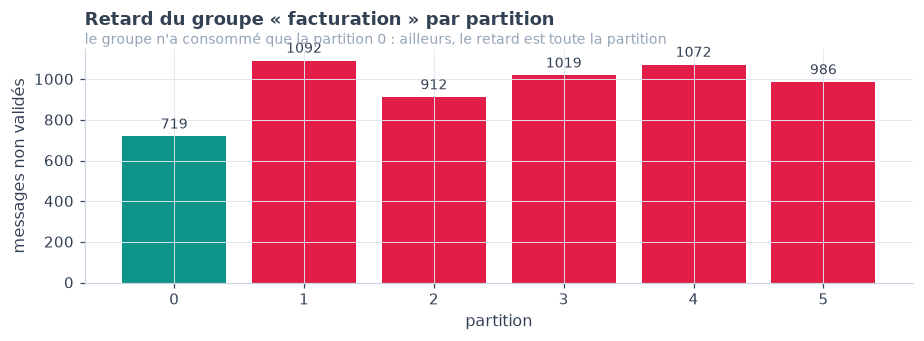

In [6]:
parts = [TopicPartition("clics", p) for p in range(6)]
c = KafkaConsumer(bootstrap_servers=B, group_id="facturation", enable_auto_commit=False)
fin = c.end_offsets(parts)
lag = {tp.partition: fin[tp] - (c.committed(tp) or 0) for tp in parts}
c.close()
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.bar(list(lag.keys()), list(lag.values()), color=[TEAL if p == 0 else ROSE for p in lag])
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("partition"); ax.set_ylabel("messages non validés")
ax.set_title("Retard du groupe « facturation » par partition")
subtitle(ax, "le groupe n'a consommé que la partition 0 : ailleurs, le retard est toute la partition")
plt.tight_layout(); plt.show()

Exactement les 50 messages traités après la dernière validation (offsets 200 à 249) sont
retraités : c'est le « au moins une fois » prévu par le cours. Le retard par partition est
la métrique à surveiller en production (outils comme `kafka-consumer-groups.sh
--describe`, qui affiche la même colonne `LAG`).

> **À retenir.** Le courtier ne stocke qu'un offset validé par partition et par groupe ; un
> remplaçant reprend là et retraite ce qui suivait. Le retard (fin du journal - offset
> validé) mesure la santé d'un consommateur.

## 4. Rejouer (section *Replaying old messages*)

Lire ne supprime rien : un **nouveau groupe** relit tout depuis le début, et un consommateur
peut repositionner son offset où il veut, à un offset précis (`seek`) ou à un instant
(`offsets_for_times`, qui cherche le premier message dont l'horodatage est postérieur).

In [7]:
nouveau_sujet("mesures", 1)
prod = producteur()
t_milieu = None
for i in range(300):
    if i == 200:
        prod.flush(); time.sleep(1.0); t_milieu = int(time.time() * 1000)
    prod.send("mesures", key=None, value={"i": i})
prod.flush()
tpm = TopicPartition("mesures", 0)
c = KafkaConsumer(bootstrap_servers=B, group_id=None, enable_auto_commit=False, value_deserializer=lambda v: json.loads(v))
c.assign([tpm])

def lire(n):
    out = []
    while len(out) < n:
        out += [r for r in c.poll(300).get(tpm, [])]
    return out[:n]

c.seek_to_beginning(tpm); a = lire(3)
c.seek(tpm, 150); b = lire(3)
off = c.offsets_for_times({tpm: t_milieu})[tpm].offset
c.seek(tpm, off); d = lire(3)
c.close()
pd.DataFrame({"depuis le début": [r.value["i"] for r in a], "seek(150)": [r.value["i"] for r in b],
              "depuis l'instant de la pause": [r.value["i"] for r in d]}, index=["1er", "2e", "3e"])

,depuis le début,seek(150),depuis l'instant de la pause
1er,0,150,200
2e,1,151,201
3e,2,152,202


L'instant choisi (pendant la pause d'une seconde après le 200e message) renvoie bien au
message 200. C'est ce qui permet de **retraiter** un intervalle de temps après la
correction d'un bogue.

> **À retenir.** Un consommateur choisit sa position : début, offset précis, ou instant ;
> rejouer est une opération ordinaire, sans effet sur les autres consommateurs.

## 5. Rétention : le début du journal avance (section *Disk space usage*)

On crée un sujet dont les segments sont fermés toutes les 500 ms et supprimés au bout de
3 s (`segment.ms`, `retention.ms`), et l'on écrit 20 messages par seconde pendant 12 s en
relevant le premier offset disponible (`beginning_offsets`) et le prochain offset à écrire
(`end_offsets`).

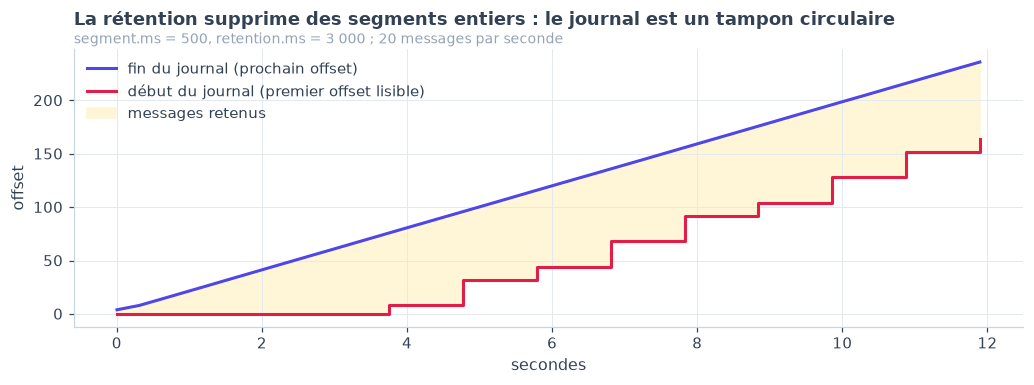

à la fin : messages retenus = 72 sur 236 écrits


In [8]:
nouveau_sujet("eph", 1, segment_ms=500, retention_ms=3000)
tpe = TopicPartition("eph", 0)
prod = producteur()
c = KafkaConsumer(bootstrap_servers=B, group_id=None)
suivi, t0 = [], time.time()
while time.time() - t0 < 12:
    for _ in range(4):
        prod.send("eph", key=None, value={"t": time.time()})
    prod.flush()
    suivi.append((time.time() - t0, c.beginning_offsets([tpe])[tpe], c.end_offsets([tpe])[tpe]))
    time.sleep(0.2)
c.close()
S = pd.DataFrame(suivi, columns=["t", "début", "fin"])
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(S.t, S.fin, color=INDIGO, label="fin du journal (prochain offset)")
ax.step(S.t, S["début"], where="post", color=ROSE, label="début du journal (premier offset lisible)")
ax.fill_between(S.t, S["début"], S.fin, step="post", color=LIGHT[AMBER], alpha=0.7, label="messages retenus")
ax.set_xlabel("secondes"); ax.set_ylabel("offset")
ax.set_title("La rétention supprime des segments entiers : le journal est un tampon circulaire")
subtitle(ax, "segment.ms = 500, retention.ms = 3 000 ; 20 messages par seconde")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"à la fin : messages retenus = {S.fin.iloc[-1] - S['début'].iloc[-1]} sur {S.fin.iloc[-1]} écrits")

Le début du journal avance **par sauts** (des segments entiers sont supprimés) et la
fenêtre retenue reste de quelques secondes de messages : un consommateur dont l'offset
tomberait sous le début du journal ne pourrait plus lire ces messages (Kafka appliquerait
alors sa politique `auto.offset.reset`).

> **À retenir.** La rétention fait avancer le début du journal segment par segment ; la
> capacité du tampon se mesure en temps de messages.